# Oasis Infobyte Data Analytics Internship (Level 2)
## Task 3: Fraud Detection using Machine Learning
**Author:** Yasmeen Akhter  
**GitHub Repository:** OIBSIP  
**Tech Stack:** Python, Pandas, NumPy, Scikit-Learn, Imbalanced-Learn (SMOTE), Matplotlib, Seaborn, Jupyter Notebook  

### Project Objective
Build a machine learning pipeline to detect fraudulent financial transactions from a heavily imbalanced dataset, handling class imbalance via SMOTE, training robust classifiers, and evaluating them using Precision, Recall, F1-Score, and AUC-ROC.

### Step 1: Load Dataset and Analyse Class Imbalance
We load the credit card transaction dataset and calculate the exact percentage of fraudulent transactions to understand the scale of class imbalance.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('creditcard.csv')

print("--- DATASET SHAPE ---")
print(df.shape)

print("\n--- CLASS DISTRIBUTION ---")
fraud_counts = df['Class'].value_counts()
print(fraud_counts)

fraud_percentage = (fraud_counts[1] / len(df)) * 100
print(f"\nFraudulent Transactions Percentage: {fraud_percentage:.4f}%")

--- DATASET SHAPE ---
(284807, 31)

--- CLASS DISTRIBUTION ---
Class
0    284315
1       492
Name: count, dtype: int64

Fraudulent Transactions Percentage: 0.1727%


### Step 2: Exploratory Data Analysis (EDA)
We compare transaction amounts for fraudulent vs. non-fraudulent transactions to identify underlying patterns.

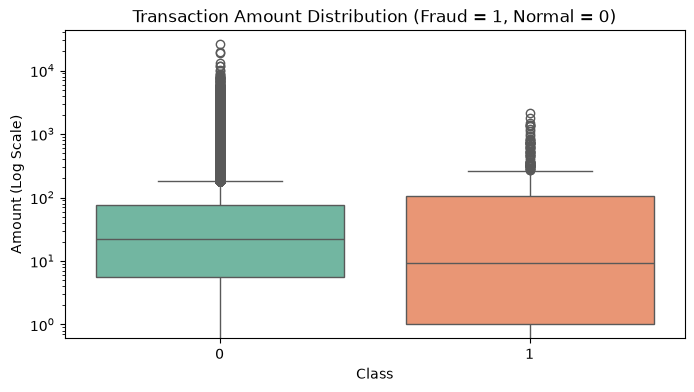

In [2]:
# Amount distribution for Fraud vs Non-Fraud
plt.figure(figsize=(8, 4))
sns.boxplot(x='Class', y='Amount', data=df, palette='Set2', hue='Class', legend=False)
plt.yscale('log') # Log scale taakey outliers saaf nazar ayen
plt.title('Transaction Amount Distribution (Fraud = 1, Normal = 0)')
plt.xlabel('Class')
plt.ylabel('Amount (Log Scale)')
plt.show()

### Step 3: Why Standard Accuracy is Misleading
In heavily imbalanced datasets (e.g., 99.8% normal and 0.2% fraud), a dummy model that simply predicts every transaction as "Normal" will achieve **99.8% accuracy**. However, it will catch **0% of frauds**. Therefore, accuracy is deeply misleading; instead, we must rely on **Precision, Recall, F1-Score, and AUC-ROC**.

### Step 4: Stratified Train/Test Split and SMOTE Oversampling
We split our data using **stratification** to preserve fraud ratios, then apply **SMOTE (Synthetic Minority Over-sampling Technique)** on the training set to balance the classes.

In [4]:
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE

X = df.drop(columns=['Class'])
y = df['Class']

# Stratified Train/Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Apply SMOTE to training data only
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

print("Before SMOTE - Training shape:", X_train.shape)
print("After SMOTE - Training shape:", X_train_smote.shape)
print("After SMOTE - Class distribution:\n", pd.Series(y_train_smote).value_counts())

Before SMOTE - Training shape: (227845, 30)
After SMOTE - Training shape: (454902, 30)
After SMOTE - Class distribution:
 Class
0    227451
1    227451
Name: count, dtype: int64


### Step 5: Training Classifiers
We train two models on the resampled data:
1. **Logistic Regression** (Baseline linear model)
2. **Random Forest Classifier** (Robust ensemble model)

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_smote_scaled = scaler.fit_transform(X_train_smote)
X_test_scaled = scaler.transform(X_test)

# Model 1: Logistic Regression 
lr_model = LogisticRegression(max_iter=2000, random_state=42)
lr_model.fit(X_train_smote_scaled, y_train_smote)
y_pred_lr = lr_model.predict(X_test_scaled)
y_prob_lr = lr_model.predict_proba(X_test_scaled)[:, 1]


rf_model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_model.fit(X_train_smote, y_train_smote)
y_pred_rf = rf_model.predict(X_test)
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

print("Models trained successfully with scaling!")

Models trained successfully with scaling!


### Step 6: Model Evaluation & Metric Analysis
We evaluate models using Precision, Recall, F1-Score, and plot the **AUC-ROC curve**.

--- Logistic Regression Evaluation ---
              precision    recall  f1-score   support

           0       1.00      0.99      0.99     56864
           1       0.13      0.90      0.23        98

    accuracy                           0.99     56962
   macro avg       0.57      0.94      0.61     56962
weighted avg       1.00      0.99      0.99     56962

AUC-ROC Score: 0.974528197604309

--- Random Forest Evaluation ---
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.84      0.83      0.83        98

    accuracy                           1.00     56962
   macro avg       0.92      0.91      0.92     56962
weighted avg       1.00      1.00      1.00     56962

AUC-ROC Score: 0.9644232605112952


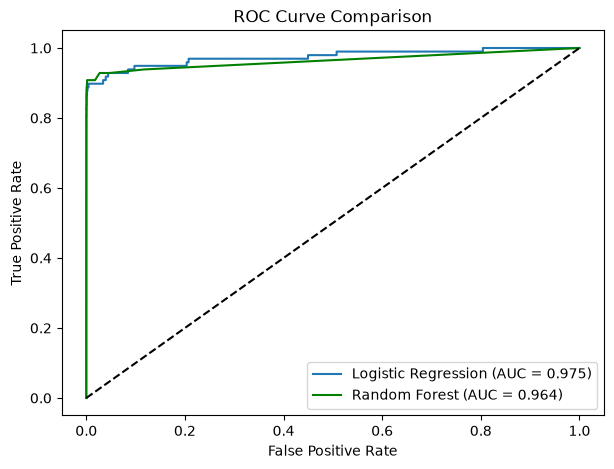

In [6]:
from sklearn.metrics import classification_report, roc_auc_score, roc_curve, confusion_matrix

print("--- Logistic Regression Evaluation ---")
print(classification_report(y_test, y_pred_lr))
print("AUC-ROC Score:", roc_auc_score(y_test, y_prob_lr))

print("\n--- Random Forest Evaluation ---")
print(classification_report(y_test, y_pred_rf))
print("AUC-ROC Score:", roc_auc_score(y_test, y_prob_rf))

# ROC Curve Plot
plt.figure(figsize=(7, 5))
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_prob_lr)
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)

plt.plot(fpr_lr, tpr_lr, label=f'Logistic Regression (AUC = {roc_auc_score(y_test, y_prob_lr):.3f})')
plt.plot(fpr_rf, tpr_rf, label=f'Random Forest (AUC = {roc_auc_score(y_test, y_prob_rf):.3f})', color='green')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison')
plt.legend()
plt.show()

### Step 7: Recall vs. Precision Trade-off in Fraud Detection
- **Recall** is the most critical metric for fraud detection because missing a fraudulent transaction (False Negative) causes direct financial loss and security breaches. We want our model to catch as many actual frauds as possible.
- **Precision** ensures we minimize False Positives (flagging legitimate transactions as fraud), preventing customer annoyance and blocked cards. Balancing both via the F1-Score is essential.

### Step 8: Scalability Discussion
To handle **1 million transactions per hour** (~278 transactions per second) in a production environment:
1. **Cloud & Distributed Computing:** Use Apache Spark (PySpark) with distributed clusters for real-time feature extraction.
2. **Model Optimization:** Deploy lightweight models (like XGBoost or quantized neural networks) on high-throughput streaming architectures (Apache Kafka).
3. **Containerisation & API:** Wrap the model in FastAPI containers deployed via Kubernetes for auto-scaling.